# TFTExplainer variable importance — iteration 4

Run from the **same folder** as notebooks 01/02 (the one containing `darts_logs/`, `series_cache/`, `column_roles.json`, `run_metadata.json`). Nothing from notebook 02 needs to be in memory.

**Run the cells in order.** Cell 1 defines the stubs the checkpoint needs to unpickle.

- Cell 1: imports and callback stubs
- Cell 2: rebuild `val_seq` / `val_cov` from the saved cache (check the printed probe line: 473 days ending 2026-09-30, covariates ending 2026-12-31)
- Cell 3: load the best checkpoint, run TFTExplainer, print tables, save CSVs and plot, stability check
- Cell 4: decoder importance for a single forecast day (`TARGET_DATE`), compared with the 92-day average
- Cell 5: diagnostics (dead inputs, counterfactuals on the 2026 forecast, in-sample Diwali-2025 backtest)

Importances are Variable Selection Network attention weights, not effect on accuracy.

## Cell 1 — imports and stubs

In [1]:
# ----- CELL 1: imports + stubs needed to unpickle the checkpoint ---------------------
import os, sys, re, json, collections.abc
sys.path.append(os.getcwd())

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from darts import TimeSeries
from darts.models import TFTModel
from darts.explainability import TFTExplainer
from pytorch_lightning import Callback

from tft_checks import EmbeddingGate          # noqa: F401  (pickled inside the checkpoint)


class TBDiagnostics(Callback):                # stub: the checkpoint pickles __main__.TBDiagnostics
    pass

The StatsForecast module could not be imported. To enable support for the AutoARIMA, AutoETS and Croston models, please consider installing it.
The `XGBoost` module could not be imported. To enable XGBoost support in Darts, follow the detailed instructions in the installation guide: https://github.com/unit8co/darts/blob/master/INSTALL.md
The `XGBoost` module could not be imported. To enable XGBoost support in Darts, follow the detailed instructions in the installation guide: https://github.com/unit8co/darts/blob/master/INSTALL.md


## Cell 2 — rebuild validation series and covariates

In [2]:
from pathlib import Path
BASE = Path(r'C:\Users\G0004878\Desktop\TFT_Data\Daily_forecasting_model\Iterations in October\Using_XGB_Features')

In [3]:
# ----- CELL 2: rebuild val_seq / val_cov from the files notebook 02 saved -------------
CACHE_DIR = os.path.join(BASE, "series_cache")
with open(os.path.join(BASE, "column_roles.json")) as f:
    ROLES = json.load(f)
with open(os.path.join(BASE, "run_metadata.json")) as f:
    MODEL_NAME = json.load(f)["model_name"]

target_col        = ROLES["target_col"]
FREQ              = ROLES["freq"]
static_covariates = ROLES["static_covariates"]
binary_covariates = ROLES["binary_covariates"]
series_covariates = ROLES["series_covariates"]
future_covariates = ROLES["future_covariates"]
CALENDAR_COLS     = ROLES["calendar_covariates"]
PETROL_COLS       = ROLES["shared_continuous_covariates"]

# same festive-window list as notebook 02, Section 0
PENALTY_COLS = ([f"N-{i}" for i in range(16, 0, -1)] + ["N"] + [f"N+{i}" for i in range(1, 11)]
                + [f"D-{i}" for i in range(3, 0, -1)] + ["D"] + [f"D+{i}" for i in range(1, 7)]
                + ["C"] + [f"C+{i}" for i in range(1, 7)])
PENALTY_COLS = [c for c in PENALTY_COLS if c in future_covariates]
OTHER_FLAGS  = [c for c in binary_covariates if c not in PENALTY_COLS]


def safe_name(key):
    return str(key).replace("<>", "_").replace("/", "_").replace("\\", "_")


series_index = pd.read_parquet(os.path.join(CACHE_DIR, "series_index.parquet"))
SPEND_PATHS  = np.load(os.path.join(CACHE_DIR, "spend_paths.npy"))
SHARED_COV   = TimeSeries.from_pickle(os.path.join(CACHE_DIR, "shared_cov.pkl"))
CAL_INDEX, CAL_VALUES = SHARED_COV.time_index, SHARED_COV.values(copy=False)
assert len(CAL_INDEX) == SPEND_PATHS.shape[1]


class TargetSeq(collections.abc.Sequence):
    def __init__(self, keys, code_rows):
        self.keys, self.code_rows, self._ram = list(keys), code_rows, {}

    def __len__(self):
        return len(self.keys)

    def __getitem__(self, i):
        if isinstance(i, slice):
            return [self[j] for j in range(*i.indices(len(self)))]
        if i < 0:
            i += len(self)
        if not 0 <= i < len(self):
            raise IndexError(i)
        if i not in self._ram:
            with np.load(os.path.join(CACHE_DIR, f"{safe_name(self.keys[i])}.npz")) as z:
                sales, start = z["val_sales"], str(z["val_start"])
            self._ram[i] = TimeSeries.from_times_and_values(
                pd.date_range(start, periods=len(sales), freq=FREQ),
                sales.reshape(-1, 1).astype(np.float32), columns=[target_col],
                static_covariates=pd.DataFrame([self.code_rows[i]], columns=static_covariates,
                                               dtype=np.float32))
        return self._ram[i]


class SeriesCov(collections.abc.Sequence):
    def __init__(self, path_ids):
        self.path_ids, self._ram = np.asarray(path_ids, dtype=np.int64), {}

    def __len__(self):
        return len(self.path_ids)

    def __getitem__(self, i):
        if isinstance(i, slice):
            return [self[j] for j in range(*i.indices(len(self)))]
        if i < 0:
            i += len(self)
        if not 0 <= i < len(self):
            raise IndexError(i)
        pid = int(self.path_ids[i])
        if pid not in self._ram:
            vals = np.concatenate([CAL_VALUES, SPEND_PATHS[pid]], axis=1).astype(np.float32, copy=False)
            self._ram[pid] = TimeSeries.from_times_and_values(CAL_INDEX, vals, columns=list(future_covariates))
        return self._ram[pid]


# identical selection and order to notebook 02: in_val series, shuffled with seed 42
sel = series_index[series_index["in_val"]].sample(frac=1.0, random_state=42)
val_seq = TargetSeq(sel["key"], sel[static_covariates].to_numpy())
val_cov = SeriesCov(sel["spend_path"].to_numpy())
print(f"val_seq: {len(val_seq):,} series | probe: {val_seq[0].start_time().date()} -> "
      f"{val_seq[0].end_time().date()} ({len(val_seq[0])} days) | cov ends {val_cov[0].end_time().date()}")

val_seq: 32,216 series | probe: 2025-06-15 -> 2026-09-30 (473 days) | cov ends 2026-12-31


In [6]:
MODEL_NAME

'daily_tft_xgb_features_2026-10-25_20_45_56'

## Cell 3 — explain, tables, plots, stability

In [11]:
BASE

WindowsPath('C:/Users/G0004878/Desktop/TFT_Data/Daily_forecasting_model/Iterations in October/Using_XGB_Features')

Using bfloat16 Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
c:\Users\G0004878\Desktop\Virtual_environments\darts_gpu\lib\site-packages\pytorch_lightning\trainer\connectors\data_connector.py:425: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=19` in the `DataLoader` to improve performance.


Predicting: |          | 0/? [00:00<?, ?it/s]

  explained series 0-256 (256/1000)


Using bfloat16 Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
c:\Users\G0004878\Desktop\Virtual_environments\darts_gpu\lib\site-packages\pytorch_lightning\trainer\connectors\data_connector.py:425: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=19` in the `DataLoader` to improve performance.


Predicting: |          | 0/? [00:00<?, ?it/s]

  explained series 256-512 (512/1000)


... (2 outputs left out)

  explained series 512-768 (768/1000)


Using bfloat16 Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
c:\Users\G0004878\Desktop\Virtual_environments\darts_gpu\lib\site-packages\pytorch_lightning\trainer\connectors\data_connector.py:425: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=19` in the `DataLoader` to improve performance.


Predicting: |          | 0/? [00:00<?, ?it/s]

  explained series 768-1000 (1000/1000)
{'decoder': 78, 'encoder': 79, 'static': 8} variables per part
{'decoder': 100.0, 'encoder': 100.0, 'static': 100.0} (sum per part)

=== ALL variables (% of VSN weight within each part) ===
                      group                    variable  decoder  encoder  static
  calendar (dow, month-end)                     DOW_SIN    3.848    1.357     NaN
  calendar (dow, month-end)                     DOW_COS    1.195    2.178     NaN
  calendar (dow, month-end)                IS_MONTH_END    1.095    1.860     NaN
  calendar (dow, month-end)           DAYS_TO_MONTH_END    0.836    1.442     NaN
  calendar (dow, month-end)              IS_MONTH_START    0.723    0.978     NaN
       festive-window flags                         N+5    3.879    0.261     NaN
       festive-window flags                           N    3.394    0.635     NaN
       festive-window flags                         D-2    2.737    3.641     NaN
       festive-window flags     

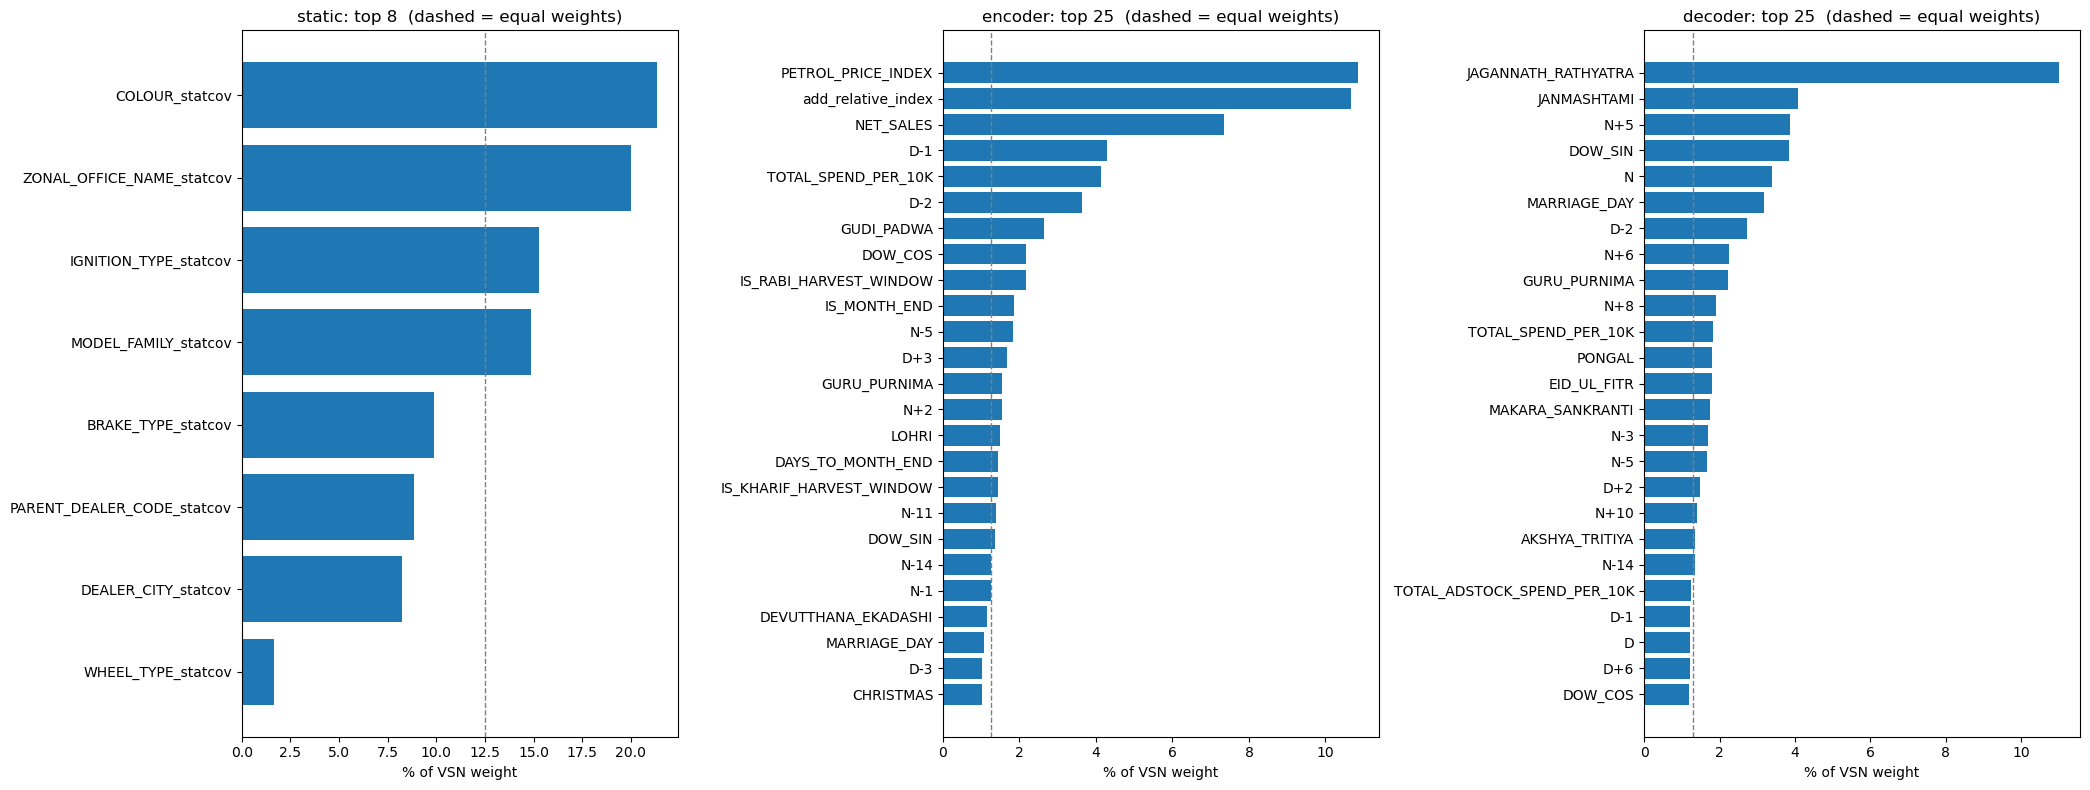

Using bfloat16 Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
c:\Users\G0004878\Desktop\Virtual_environments\darts_gpu\lib\site-packages\pytorch_lightning\trainer\connectors\data_connector.py:425: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=19` in the `DataLoader` to improve performance.


Predicting: |          | 0/? [00:00<?, ?it/s]

  explained series 1000-1256 (256/1000)


Using bfloat16 Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
c:\Users\G0004878\Desktop\Virtual_environments\darts_gpu\lib\site-packages\pytorch_lightning\trainer\connectors\data_connector.py:425: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=19` in the `DataLoader` to improve performance.


Predicting: |          | 0/? [00:00<?, ?it/s]

  explained series 1256-1512 (512/1000)


... (2 outputs left out)

  explained series 1512-1768 (768/1000)


Using bfloat16 Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
c:\Users\G0004878\Desktop\Virtual_environments\darts_gpu\lib\site-packages\pytorch_lightning\trainer\connectors\data_connector.py:425: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=19` in the `DataLoader` to improve performance.


Predicting: |          | 0/? [00:00<?, ?it/s]

  explained series 1768-2000 (1000/1000)
rank agreement (Spearman), two disjoint samples, static  : 1.000
rank agreement (Spearman), two disjoint samples, encoder : 0.999
rank agreement (Spearman), two disjoint samples, decoder : 0.995


In [13]:
# ----- CELL 3: load model + explain ---------------------------------------------------
N_EXPLAIN     = 1000
RUN_STABILITY = True
TOP_K_PLOT    = 25
WORK_DIR      = BASE / "darts_logs"

best = TFTModel.load_from_checkpoint(MODEL_NAME, work_dir=str(WORK_DIR), best=True)


def clean_name(name):
    name = str(name)
    m = re.fullmatch(r"static_covariate_(\d+)", name)
    if m:
        return static_covariates[int(m.group(1))]
    return re.sub(r"_(fut_cov|past_cov|static_cov|target|futcov|pastcov)$", "", name)


def group_of(part, var):
    if part == "static":
        return "static (embedded)"
    if var == target_col:
        return "past sales (target history)"
    if "relative_index" in var:
        return "relative index"
    if var in series_covariates:
        return "spend (per-series)"
    if var in PETROL_COLS:
        return "petrol"
    if var in CALENDAR_COLS:
        return "calendar (dow, month-end)"
    if var in PENALTY_COLS:
        return "festive-window flags"
    if var in OTHER_FLAGS:
        return "other binary flags"
    return "UNMATCHED"


def _explain_chunk(ser, cov):
    """TFTExplainer needs len(series) <= model.batch_size, so it is called on chunks."""
    explainer = TFTExplainer(best, background_series=ser, background_future_covariates=cov)
    result = explainer.explain()
    try:
        w = result.get_feature_importances()
    except AttributeError:
        w = dict(encoder_importance=result.get_encoder_importance(),
                 decoder_importance=result.get_decoder_importance(),
                 static_covariates_importance=result.get_static_covariates_importance())
    means = {}
    for key, part in [("encoder_importance", "encoder"), ("decoder_importance", "decoder"),
                      ("static_covariates_importance", "static")]:
        df = w.get(key)
        if df is None:
            continue
        if isinstance(df, list):                   # one DataFrame per background series
            df = [d for d in df if d is not None and len(d)]
            if not df:
                continue
            df = pd.concat(df, ignore_index=True)
        if len(df) == 0:
            continue
        means[part] = df.mean(axis=0)
    return means, result, explainer


def explain_sample(lo, hi):
    bs = best.batch_size                           # 256 for this model
    acc, n_total = {}, 0
    for a in range(lo, hi, bs):
        b = min(a + bs, hi)
        ser = [val_seq[i] for i in range(a, b)]
        cov = [val_cov[i] for i in range(a, b)]
        assert all(c.end_time() >= s_.end_time() + best.output_chunk_length * s_.freq
                   for s_, c in zip(ser, cov)), "future covariates do not reach FORECAST_END"
        means, result, explainer = _explain_chunk(ser, cov)
        n = b - a
        for part, s_ in means.items():             # size-weighted running sum of per-chunk means
            acc[part] = s_ * n if part not in acc else acc[part] + s_ * n
        n_total += n
        print(f"  explained series {a}-{b} ({n_total}/{hi - lo})")
    rows = []
    for part, total in acc.items():
        s_ = total / n_total
        s_ = s_ * (100.0 / s_.sum())               # force % within each part, whatever the raw scale
        for name, val in s_.items():
            v = clean_name(name)
            rows.append(dict(part=part, variable=v, importance_pct=float(val), group=group_of(part, v)))
    out = pd.DataFrame(rows)
    out["uniform_pct"] = 100.0 / out.groupby("part")["variable"].transform("count")
    out["x_uniform"] = out["importance_pct"] / out["uniform_pct"]
    return out, result, explainer


hi1 = min(N_EXPLAIN, len(val_seq))
imp, result, explainer = explain_sample(0, hi1)   # result/explainer = last chunk only
imp = imp.sort_values(["part", "importance_pct"], ascending=[True, False]).reset_index(drop=True)

bad = imp[imp["group"] == "UNMATCHED"]
if len(bad):
    print("*** UNMATCHED variable names (fix clean_name / group_of):", bad["variable"].tolist()[:10])
print(imp.groupby("part").size().to_dict(), "variables per part")
print(imp.groupby("part")["importance_pct"].sum().round(2).to_dict(), "(sum per part)")

wide = (imp.pivot_table(index=["group", "variable"], columns="part",
                        values="importance_pct", aggfunc="first").reset_index())
print("\n=== ALL variables (% of VSN weight within each part) ===")
sort_cols = ["group"] + (["decoder"] if "decoder" in wide.columns else [])
print(wide.sort_values(sort_cols, ascending=[True] + [False] * (len(sort_cols) - 1))
          .round(3).to_string(index=False))

grp = imp.groupby(["part", "group"])["importance_pct"].sum().unstack("part").fillna(0).round(2)
n_vars = imp.groupby(["part", "group"]).size().unstack("part").fillna(0).astype(int).add_prefix("n_vars_")
print("\n=== By group ===")
print(grp.join(n_vars).to_string())

imp.to_csv(os.path.join(BASE, "tft_variable_importance_long.csv"), index=False)
wide.to_csv(os.path.join(BASE, "tft_variable_importance_wide.csv"), index=False)

parts = [p for p in ["static", "encoder", "decoder"] if p in imp["part"].unique()]
fig, axes = plt.subplots(1, len(parts), figsize=(7 * len(parts), 8))
axes = np.atleast_1d(axes)
for ax, p in zip(axes, parts):
    g = imp[imp["part"] == p].nlargest(TOP_K_PLOT, "importance_pct").sort_values("importance_pct")
    ax.barh(g["variable"], g["importance_pct"])
    ax.axvline(g["uniform_pct"].iloc[0], ls="--", c="grey", lw=1)
    ax.set_title(f"{p}: top {min(TOP_K_PLOT, len(g))}  (dashed = equal weights)")
    ax.set_xlabel("% of VSN weight")
plt.tight_layout()
plt.savefig(os.path.join(BASE, "tft_variable_importance.png"), dpi=150)
plt.show()

hi2 = min(2 * N_EXPLAIN, len(val_seq))
if RUN_STABILITY and hi2 > hi1:
    imp_b, _, _ = explain_sample(hi1, hi2)
    for p in parts:
        a = imp[imp.part == p].set_index("variable")["importance_pct"]
        b = imp_b[imp_b.part == p].set_index("variable")["importance_pct"].reindex(a.index)
        print(f"rank agreement (Spearman), two disjoint samples, {p:8s}: {a.corr(b, method='spearman'):.3f}")
elif RUN_STABILITY:
    print("Not enough series for a second disjoint sample; stability check skipped.")

## Cell 4 — importance for one forecast day (2026-11-06)

In [16]:
# ----- CELL 4: importance for ONE forecast day (2026-11-06) ----------------------------
# Needs cells 1-3 run first (uses best, val_seq, val_cov, clean_name, group_of, SHARED_COV).
TARGET_DATE   = pd.Timestamp("2026-11-06")
N_EXPLAIN_DAY = 1000
TOP_K_DAY     = 20

FC_START = pd.Timestamp(ROLES["forecast_start"])
H0       = (TARGET_DATE - FC_START).days                        # 0-based step inside the horizon
assert 0 <= H0 < best.output_chunk_length, "TARGET_DATE is outside the forecast window"
print(f"{TARGET_DATE.date()} is forecast step {H0 + 1} of {best.output_chunk_length} "
      f"(window starts {FC_START.date()})")

# which festive / calendar flags are switched on for that day (from the shared calendar)
_cal_df = SHARED_COV.to_dataframe() if hasattr(SHARED_COV, "to_dataframe") else SHARED_COV.pd_dataframe()
if TARGET_DATE not in _cal_df.index:
    raise KeyError(f"{TARGET_DATE.date()} not in SHARED_COV "
                   f"({SHARED_COV.start_time().date()} to {SHARED_COV.end_time().date()})")
_cal_row = _cal_df.loc[TARGET_DATE]
print("binary flags = 1 on that day:", [c for c in binary_covariates if _cal_row[c] == 1.0] or "none")


def _stack(x):
    """Darts returns one DataFrame per background series -> stack into one table."""
    if x is None:
        return None
    if isinstance(x, list):
        x = [d for d in x if d is not None and len(d)]
        return pd.concat(x, ignore_index=True) if x else None
    return x if len(x) else None


def _raw_weights(ser, cov):
    explainer = TFTExplainer(best, background_series=ser, background_future_covariates=cov)
    result = explainer.explain()
    try:
        w = result.get_feature_importances()
    except AttributeError:
        w = dict(encoder_importance=result.get_encoder_importance(),
                 decoder_importance=result.get_decoder_importance(),
                 static_covariates_importance=result.get_static_covariates_importance())
    return {k: _stack(v) for k, v in w.items()}


def _day_weights(dec_cols, n_series):
    """Per-step decoder VSN weights from the last forward pass, mean over series at step H0."""
    t = getattr(best.model, "_decoder_sparse_weights", None)
    if t is None:
        raise RuntimeError("best.model has no _decoder_sparse_weights; per-day weights unavailable "
                           "in this Darts version.")
    arr = t.detach().cpu().numpy()
    arr = arr.reshape(arr.shape[0], arr.shape[1], -1)            # (series, step, variable)
    if arr.shape[0] != n_series or arr.shape[1] != best.output_chunk_length or arr.shape[2] != len(dec_cols):
        raise RuntimeError(f"Unexpected decoder weight shape {t.shape}; expected "
                           f"({n_series}, {best.output_chunk_length}, ..., {len(dec_cols)}).")
    return pd.Series(arr[:, H0, :].mean(axis=0), index=dec_cols)


bs    = best.batch_size
n_max = min(N_EXPLAIN_DAY, len(val_seq))
acc_day, acc_avg, acc_enc, acc_stat, n_tot = None, None, None, None, 0
for a in range(0, n_max, bs):
    b = min(a + bs, n_max)
    ser = [val_seq[i] for i in range(a, b)]
    cov = [val_cov[i] for i in range(a, b)]
    w   = _raw_weights(ser, cov)
    dec = w["decoder_importance"]
    n   = b - a
    if a == 0:
        print("decoder importance table (stacked): shape", dec.shape)
    day = _day_weights(dec.columns, n) * n
    avg = dec.mean(axis=0) * n
    acc_day = day if acc_day is None else acc_day + day
    acc_avg = avg if acc_avg is None else acc_avg + avg
    e = w["encoder_importance"].mean(axis=0) * n
    acc_enc = e if acc_enc is None else acc_enc + e
    st_ = w.get("static_covariates_importance")
    if st_ is not None:
        v = st_.mean(axis=0) * n
        acc_stat = v if acc_stat is None else acc_stat + v
    n_tot += n
    print(f"  explained series {a}-{b} ({n_tot}/{n_max})")


def _tidy(total, part):
    s_ = total / n_tot
    s_ = s_ * (100.0 / s_.sum())
    return pd.DataFrame({"part": part, "variable": [clean_name(x) for x in s_.index],
                         "importance_pct": s_.values})


day_df  = _tidy(acc_day, "decoder (day)")
avg_df  = _tidy(acc_avg, "decoder (all days)")
dec_cmp = day_df.merge(avg_df[["variable", "importance_pct"]], on="variable", suffixes=("_day", "_avg"))
dec_cmp["group"]         = [group_of("decoder", v) for v in dec_cmp["variable"]]
dec_cmp["x_uniform_day"] = dec_cmp["importance_pct_day"] / (100.0 / len(dec_cmp))
dec_cmp["day_minus_avg"] = dec_cmp["importance_pct_day"] - dec_cmp["importance_pct_avg"]
dec_cmp = dec_cmp.drop(columns="part").sort_values("importance_pct_day", ascending=False)

print(f"\n=== DECODER, {TARGET_DATE.date()} (top {TOP_K_DAY}); uniform = {100.0 / len(dec_cmp):.2f}% ===")
print(dec_cmp.head(TOP_K_DAY).round(3).to_string(index=False))
print(f"\n=== DECODER by group: this day vs average over the {best.output_chunk_length} days (% summed) ===")
print(dec_cmp.groupby("group")[["importance_pct_day", "importance_pct_avg"]].sum().round(2)
      .sort_values("importance_pct_day", ascending=False).to_string())

enc_df = _tidy(acc_enc, "encoder")
enc_df["group"] = [group_of("encoder", v) for v in enc_df["variable"]]
print("\n=== ENCODER (window-level; same for every forecast day) top 10 ===")
print(enc_df.sort_values("importance_pct", ascending=False).head(10).round(3).to_string(index=False))
if acc_stat is not None:
    st_df = _tidy(acc_stat, "static")
    print("\n=== STATIC (same for every forecast day) ===")
    print(st_df.sort_values("importance_pct", ascending=False).round(3).to_string(index=False))

dec_cmp.to_csv(os.path.join(BASE, f"tft_decoder_importance_{TARGET_DATE.date()}.csv"), index=False)

Using bfloat16 Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


2026-11-06 is forecast step 37 of 92 (window starts 2026-10-01)
binary flags = 1 on that day: ['D-2', 'IS_KHARIF_HARVEST_WINDOW', 'POST_GST_CUT']


c:\Users\G0004878\Desktop\Virtual_environments\darts_gpu\lib\site-packages\pytorch_lightning\trainer\connectors\data_connector.py:425: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=19` in the `DataLoader` to improve performance.


Predicting: |          | 0/? [00:00<?, ?it/s]

Using bfloat16 Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


decoder importance table (stacked): shape (256, 78)
  explained series 0-256 (256/1000)


... (7 outputs left out)

  explained series 512-768 (768/1000)


c:\Users\G0004878\Desktop\Virtual_environments\darts_gpu\lib\site-packages\pytorch_lightning\trainer\connectors\data_connector.py:425: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=19` in the `DataLoader` to improve performance.


Predicting: |          | 0/? [00:00<?, ?it/s]

  explained series 768-1000 (1000/1000)

=== DECODER, 2026-11-06 (top 20); uniform = 1.28% ===
              variable  importance_pct_day  importance_pct_avg                     group  x_uniform_day  day_minus_avg
               DOW_SIN               4.487               3.848 calendar (dow, month-end)          3.499          0.639
     DAYS_TO_MONTH_END               4.313               0.836 calendar (dow, month-end)          3.364          3.477
            IS_WEEKEND               4.294               0.958        other binary flags          3.350          3.336
IS_RABI_HARVEST_WINDOW               4.255               0.913        other binary flags          3.319          3.343
                   N-7               4.118               1.130      festive-window flags          3.212          2.988
                 LOHRI               3.284               1.172        other binary flags          2.562          2.112
                   N-6               2.867               1.184      fest

## Cell 5 — diagnostics: why was 2026-11-06 under-predicted?

In [18]:
# ----- CELL 5: why was 2026-11-06 under-predicted? diagnostics --------------------------
# Needs cells 1-4 run first (uses best, val_seq, val_cov, SHARED_COV, imp, TARGET_DATE, H0, ...).
N_DIAG      = 256          # series per diagnostic (kept <= batch size)
N_SAMPLES   = 100          # NegativeBinomial samples per series
FC_START    = pd.Timestamp(ROLES["forecast_start"])
TARGET_DATE = pd.Timestamp("2026-11-06")
H0          = (TARGET_DATE - FC_START).days


def _to_df(ts):
    """Darts renamed pd_dataframe() -> to_dataframe(); support both."""
    return ts.to_dataframe() if hasattr(ts, "to_dataframe") else ts.pd_dataframe()


cal_df = _to_df(SHARED_COV)
PETROL_REF_DATE = pd.Timestamp("2025-10-18")
for col in ["D-2", "PETROL_PRICE_INDEX"]:
    assert col in cal_df.columns, f"{col} not in SHARED_COV columns"
assert PETROL_REF_DATE in cal_df.index, f"{PETROL_REF_DATE.date()} not in SHARED_COV"

# ---- D1: decoder weight sitting on flags that never fire in Oct-Dec 2026 ---------------
fc_cal = cal_df.loc[ROLES["forecast_start"]:ROLES["forecast_end"]]
dead = [c for c in binary_covariates if fc_cal[c].max() == 0]
d = imp[imp.part == "decoder"]
print(f"D1: {len(dead)} of {len(binary_covariates)} binary flags never fire in the forecast window; "
      f"they hold {d[d.variable.isin(dead)].importance_pct.sum():.1f}% of decoder VSN weight")
print(d[d.variable.isin(dead)].nlargest(8, "importance_pct")[["variable", "importance_pct"]]
      .round(2).to_string(index=False))
print("D-2 flag fires on:", [x.date().isoformat() for x in cal_df.index[cal_df["D-2"] == 1]])
print("   (each training year contributes ONE D-2 day per series)\n")


# ---- helpers ---------------------------------------------------------------------------
def predict_samples(ser, cov, n=None, ns=N_SAMPLES):
    n = n or best.output_chunk_length
    preds = best.predict(n=n, series=ser, future_covariates=cov, num_samples=ns, verbose=False)
    vals = np.stack([p.all_values(copy=False)[:, 0, :] for p in preds])      # (series, days, samples)
    return preds[0].time_index, vals


def edit_cov(cov, start, edits):
    cols = list(cov.components)
    vals = cov.values().copy()
    i0 = int((start - cov.start_time()).days)
    for c, v in edits.items():
        vals[i0:, cols.index(c)] = v
    return TimeSeries.from_times_and_values(cov.time_index, vals, columns=cols)


_cache = {}
def edited(covs, edits, tag):
    out = []
    for c in covs:
        k = (tag, id(c))
        if k not in _cache:
            _cache[k] = edit_cov(c, FC_START, edits)
        out.append(_cache[k])
    return out


n_diag = min(N_DIAG, len(val_seq))
ser  = [val_seq[i] for i in range(n_diag)]
covs = [val_cov[i] for i in range(n_diag)]
assert len(ser) <= best.batch_size

# ---- D2: counterfactuals on the 2026 forecast ------------------------------------------
z_petrol_2025 = float(cal_df.loc[PETROL_REF_DATE, "PETROL_PRICE_INDEX"])
scenarios = {
    "baseline": covs,
    "petrol -> Oct-2025 level": edited(covs, {"PETROL_PRICE_INDEX": z_petrol_2025}, "p25"),
    "petrol -> training mean": edited(covs, {"PETROL_PRICE_INDEX": 0.0}, "p0"),
    "D-2 flag off": edited(covs, {"D-2": 0.0}, "d2off"),
    "all N/D/C window flags off": edited(covs, {c: 0.0 for c in PENALTY_COLS}, "festoff"),
}
rows = []
for name, cv in scenarios.items():
    _, v = predict_samples(ser, cv)
    mean_day = v.mean(axis=2).sum(axis=0)                  # summed over the series, per day
    med_day  = np.median(v, axis=2).sum(axis=0)
    rows.append(dict(scenario=name, nov6_sum_of_means=mean_day[H0], nov6_sum_of_medians=med_day[H0],
                     uplift_vs_window_avg=mean_day[H0] / mean_day.mean()))
res = pd.DataFrame(rows)
res["vs_baseline"] = res["nov6_sum_of_means"] / res.loc[0, "nov6_sum_of_means"]
print(f"D2: forecast for {TARGET_DATE.date()} on {n_diag} series, scenario by scenario")
print(res.round(3).to_string(index=False))
print("   sum_of_medians << sum_of_means => sparse counts: point forecasts taken as the median understate totals\n")

# ---- D3: in-sample backtest of Diwali 2025 (model was trained on this period) ----------
def train_series(i):
    with np.load(os.path.join(CACHE_DIR, f"{safe_name(val_seq.keys[i])}.npz")) as z:
        sales, start = z["train_sales"], str(z["train_start"])
    return TimeSeries.from_times_and_values(
        pd.date_range(start, periods=len(sales), freq=FREQ), sales.reshape(-1, 1).astype(np.float32),
        columns=[target_col], static_covariates=val_seq[i].static_covariates)


CUT     = pd.Timestamp("2025-09-30")
OCL     = best.output_chunk_length
win_end = CUT + pd.Timedelta(days=OCL)
assert all(c.start_time() <= CUT - pd.Timedelta(days=best.input_chunk_length - 1) and c.end_time() >= win_end
           for c in covs), "val_cov does not cover the 2025 backtest window; pass covariates spanning 2025"

full_ts = [train_series(i) for i in range(n_diag)]
assert all(t.end_time() >= win_end for t in full_ts), "training sales end before 2025-12-31"
hist = [t.slice(CUT - pd.Timedelta(days=best.input_chunk_length - 1), CUT) for t in full_ts]
idx25, v25 = predict_samples(hist, covs)
assert idx25[0] == CUT + pd.Timedelta(days=1)
pred25 = v25.mean(axis=2).sum(axis=0)
act25  = np.sum([t.slice(CUT + pd.Timedelta(days=1), win_end).values()[:, 0] for t in full_ts], axis=0)
h25    = (PETROL_REF_DATE - (CUT + pd.Timedelta(days=1))).days
print(f"D3: in-sample backtest, window {(CUT + pd.Timedelta(days=1)).date()} -> {win_end.date()} (same series, same model)")
print(f"   actual    D-2 day {act25[h25]:9.0f} | uplift vs window avg {act25[h25] / act25.mean():.2f}x")
print(f"   predicted D-2 day {pred25[h25]:9.0f} | uplift vs window avg {pred25[h25] / pred25.mean():.2f}x")
print(f"   whole-window predicted / actual: {pred25.sum() / act25.sum():.2f}")
print("   If the peak is also missed here, the model cannot fit it at all (training budget / capacity / loss).")
print("   If it is caught here but missed for 2026, the failure is generalisation (covariate shift, rare flag).")

Using bfloat16 Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


D1: 28 of 69 binary flags never fire in the forecast window; they hold 38.1% of decoder VSN weight
           variable  importance_pct
JAGANNATH_RATHYATRA           11.01
        JANMASHTAMI            4.09
       GURU_PURNIMA            2.22
             PONGAL            1.81
        EID_UL_FITR            1.80
   MAKARA_SANKRANTI            1.75
     AKSHYA_TRITIYA            1.34
               N-14            1.34
D-2 flag fires on: ['2023-11-10', '2024-10-29', '2025-10-18', '2026-11-06']
   (each training year contributes ONE D-2 day per series)



c:\Users\G0004878\Desktop\Virtual_environments\darts_gpu\lib\site-packages\pytorch_lightning\trainer\connectors\data_connector.py:425: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=19` in the `DataLoader` to improve performance.
Using bfloat16 Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
Using bfloat16 Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
Using bfloat16 Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
Using bfloat16 Automatic Mixed Precision (AMP)

D2: forecast for 2026-11-06 on 256 series, scenario by scenario
                  scenario  nov6_sum_of_means  nov6_sum_of_medians  uplift_vs_window_avg  vs_baseline
                  baseline         598.799988                460.0                 6.786        1.000
  petrol -> Oct-2025 level        1556.800049               1344.0                 9.919        2.600
   petrol -> training mean        1289.260010               1101.5                 8.424        2.153
              D-2 flag off          72.309998                 26.5                 0.877        0.121
all N/D/C window flags off          74.440002                 29.0                 1.041        0.124
   sum_of_medians << sum_of_means => sparse counts: point forecasts taken as the median understate totals



Using bfloat16 Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
c:\Users\G0004878\Desktop\Virtual_environments\darts_gpu\lib\site-packages\pytorch_lightning\trainer\connectors\data_connector.py:425: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=19` in the `DataLoader` to improve performance.


D3: in-sample backtest, window 2025-10-01 -> 2025-12-31 (same series, same model)
   actual    D-2 day      1754 | uplift vs window avg 11.49x
   predicted D-2 day      1398 | uplift vs window avg 9.86x
   whole-window predicted / actual: 0.93
   If the peak is also missed here, the model cannot fit it at all (training budget / capacity / loss).
   If it is caught here but missed for 2026, the failure is generalisation (covariate shift, rare flag).


In [19]:
import torch

FLAG       = "JAGANNATH_RATHYATRA"
N_CONTROLS = 3          # how many high-weight AND low-weight never-firing flags to use as controls
SEED       = 0

for _n in ["best", "ser", "covs", "imp", "cal_df", "predict_samples", "H0", "TARGET_DATE",
           "binary_covariates", "ROLES", "TimeSeries"]:
    assert _n in globals(), f"{_n} is not defined: run cells 1-5 first"

fc_days = pd.date_range(ROLES["forecast_start"], ROLES["forecast_end"], freq="D")
nov6    = pd.DatetimeIndex([TARGET_DATE])
assert len(fc_days) == best.output_chunk_length

# ---- which flags never fire in the forecast window, and when FLAG fires in history ---------------
fc_cal = cal_df.loc[fc_days[0]:fc_days[-1]]
dead   = [c for c in binary_covariates if fc_cal[c].max() == 0]
assert FLAG in dead, f"{FLAG} is not constant 0 over the forecast window"
firing = cal_df.index[cal_df[FLAG] == 1]
print(f"{FLAG} equals 1 on {len(firing)} day(s) in the whole calendar: "
      f"{[d.date().isoformat() for d in firing]}")
print("  -> setting it to 1 on many forecast days is far outside what the model saw in training.\n")

# ---- controls: other never-firing single-day festivals, highest and lowest decoder weight ---------
weight = imp[imp.part == "decoder"].set_index("variable")["importance_pct"]
pool = (imp[(imp.part == "decoder") & (imp.group == "other binary flags")
            & imp.variable.isin(dead) & (imp.variable != FLAG)]
        .sort_values("importance_pct", ascending=False))
controls = list(pool.variable.head(N_CONTROLS)) + list(pool.variable.tail(N_CONTROLS))
print("decoder weight of", FLAG, f"= {weight.get(FLAG, np.nan):.2f}%")
print("controls (never fire in Oct-Dec):", {c: round(float(weight[c]), 2) for c in controls}, "\n")


# ---- helpers ---------------------------------------------------------------------------------------
def set_days(cov, col, dates, value=1.0):
    """Copy of a covariate series with one column set to `value` on the given dates."""
    cols = list(cov.components)
    vals = cov.values().copy()
    rows = cov.time_index.get_indexer(dates)
    assert (rows >= 0).all(), "dates fall outside the covariate range"
    vals[rows, cols.index(col)] = value
    return TimeSeries.from_times_and_values(cov.time_index, vals, columns=cols)


def with_flag(col, dates):
    cache, out = {}, []                     # many series share one covariate object: edit each once
    for c in covs:
        if id(c) not in cache:
            cache[id(c)] = set_days(c, col, dates)
        out.append(cache[id(c)])
    return out


def run(cov_list, seed=SEED):
    torch.manual_seed(seed)                 # same random draws for every scenario -> fair comparison
    _, v = predict_samples(ser, cov_list)   # (series, days, samples)
    return v.mean(axis=2).sum(axis=0)       # mean forecast, summed over the series, per day


# ---- run the scenarios ---------------------------------------------------------------------------------
base   = run(covs, SEED)
base_b = run(covs, SEED + 1)                # identical inputs, different draws = sampling noise floor
rows   = []


def record(name, daily, w=np.nan):
    ratio = (daily + 1.0) / (base + 1.0)    # +1 only guards against division by zero
    k = int(np.argmax(np.abs(np.log(ratio))))
    rows.append(dict(scenario=name, decoder_weight_pct=w, nov6=daily[H0], nov6_x=daily[H0] / base[H0],
                     total_x=daily.sum() / base.sum(), biggest_day=fc_days[k].date(), biggest_day_x=ratio[k]))


record("baseline, other random draws (noise floor)", base_b)
record(f"{FLAG}=1 on Nov 6 only", run(with_flag(FLAG, nov6)), weight.get(FLAG, np.nan))
record(f"{FLAG}=1 on all 92 days", run(with_flag(FLAG, fc_days)), weight.get(FLAG, np.nan))
for f in controls:
    record(f"control {f}=1 on all 92 days", run(with_flag(f, fc_days)), weight.get(f, np.nan))

res = pd.DataFrame(rows)
print(f"baseline: Nov 6 = {base[H0]:.1f} units over {len(ser)} series; 92-day total = {base.sum():.0f}")
print(res.round(3).to_string(index=False))

noise = abs(base_b[H0] / base[H0] - 1) * 100
print(f"\nSampling noise on Nov 6 is about {noise:.1f}%, and {abs(base_b.sum() / base.sum() - 1) * 100:.1f}% on the 92-day total. "
      "Treat changes of that size as zero.")

ctrl = res[res.scenario.str.contains("all 92 days")].copy()
ctrl["abs_log_total_x"] = np.abs(np.log(ctrl["total_x"]))
if ctrl["decoder_weight_pct"].notna().sum() >= 4:
    rho = ctrl["decoder_weight_pct"].corr(ctrl["abs_log_total_x"], method="spearman")
    print(f"Spearman between decoder weight and size of response (n={len(ctrl)} flags): {rho:.2f}  (tiny sample, read loosely)")

print("""
How to read it:
- Rath Yatra rows within the noise floor      -> the model ignores the flag; its decoder weight is a parking slot.
- Large change on 'all 92 days' only          -> the model reacts to the flag, but this scenario is out of distribution,
                                                 so it shows sensitivity, not that the weight was informative.
- Large change on 'Nov 6 only'                -> the model lets one flag move a single day; compare with D-2 (-88%).
- Controls with LOW weight moving as much as high-weight ones -> weight does not predict response.""")


Using bfloat16 Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


JAGANNATH_RATHYATRA equals 1 on 4 day(s) in the whole calendar: ['2023-06-20', '2024-07-07', '2025-06-27', '2026-07-16']
  -> setting it to 1 on many forecast days is far outside what the model saw in training.

decoder weight of JAGANNATH_RATHYATRA = 11.01%
controls (never fire in Oct-Dec): {'JANMASHTAMI': 4.09, 'GURU_PURNIMA': 2.22, 'PONGAL': 1.81, 'HARTALIK_TEEJ': 0.31, 'BUDDHA_PURNIMA': 0.22, 'VISHWAKARMA_PUJA': 0.18} 



Using bfloat16 Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
Using bfloat16 Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
Using bfloat16 Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
Using bfloat16 Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
Using bfloat16 Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - C

baseline: Nov 6 = 598.7 units over 256 series; 92-day total = 8116
                                  scenario  decoder_weight_pct        nov6  nov6_x  total_x biggest_day  biggest_day_x
baseline, other random draws (noise floor)                 NaN  594.330017   0.993    0.999  2026-10-04          0.925
       JAGANNATH_RATHYATRA=1 on Nov 6 only              11.006  911.599976   1.523    1.040  2026-11-06          1.522
      JAGANNATH_RATHYATRA=1 on all 92 days              11.006 1116.459961   1.865    2.941  2026-11-14          7.198
      control JANMASHTAMI=1 on all 92 days               4.091  527.760010   0.881    1.215  2026-11-22          1.979
     control GURU_PURNIMA=1 on all 92 days               2.219  770.969971   1.288    1.215  2026-11-22          2.194
           control PONGAL=1 on all 92 days               1.809  479.010010   0.800    1.086  2026-10-20          1.537
    control HARTALIK_TEEJ=1 on all 92 days               0.308  590.559998   0.986    0.998  2026-11

In [20]:
FLAG = "JAGANNATH_RATHYATRA"
for _n in ["best", "ser", "covs", "cal_df", "_raw_weights", "clean_name", "with_flag", "nov6",
           "TARGET_DATE", "ROLES", "binary_covariates"]:
    assert _n in globals(), f"{_n} is not defined: run cells 1-6 first"


def per_day_weights(cov_list):
    """Decoder variable-selection weights, mean over series: DataFrame (92 forecast days x 78 variables), % per day."""
    w = _raw_weights(ser, cov_list)                       # one explainer pass; leaves per-step weights on the model
    cols = [clean_name(c) for c in w["decoder_importance"].columns]
    t = best.model._decoder_sparse_weights.detach().cpu().numpy()
    t = t.reshape(t.shape[0], t.shape[1], -1)             # (series, 92 days, 78 variables)
    assert t.shape[0] == len(ser) and t.shape[2] == len(cols), f"unexpected weight shape {t.shape}"
    m = t.mean(axis=0)
    m = m / m.sum(axis=1, keepdims=True) * 100.0          # each day sums to 100%
    return pd.DataFrame(m, index=pd.date_range(ROLES["forecast_start"], periods=m.shape[0], freq="D"), columns=cols)


# ---- 1. the flag's weight on every forecast day, flag OFF (the real forecast) ---------------------------
W_off = per_day_weights(covs)
s = W_off[FLAG]
print(f"{FLAG} decoder weight over the 92 days: mean {s.mean():.1f}%  median {s.median():.1f}%  "
      f"min {s.min():.2f}%  max {s.max():.1f}%")
print(f"days with weight above 10%: {int((s > 10).sum())} of {len(s)}")
print("\nhighest-weight days (%):");  print(s.nlargest(8).round(1).to_string())
print("\nlowest-weight days (%):");   print(s.nsmallest(8).round(2).to_string())
print("\nmean weight by weekday (0 = Monday):");  print(s.groupby(s.index.dayofweek).mean().round(1).to_string())
print("\nmean weight by month:");                 print(s.groupby(s.index.month).mean().round(1).to_string())

# ---- 2. is it a 'resting slot' that empties when a real festival flag is active? -----------------------
festival_cols = [c for c in binary_covariates if not c.startswith("IS_") and c != "POST_GST_CUT"]
n_active = cal_df.loc[W_off.index, festival_cols].sum(axis=1)
print(f"\ncorrelation of the flag's weight with the number of festival flags ON that day: {s.corr(n_active):.2f}")
print(f"mean weight on days with no festival flag on : {s[n_active == 0].mean():.1f}%  ({int((n_active == 0).sum())} days)")
print(f"mean weight on days with a festival flag on  : {s[n_active > 0].mean():.1f}%  ({int((n_active > 0).sum())} days)")

# ---- 3. what happens to the weight on Nov 6 when the flag really fires --------------------------------
W_on = per_day_weights(with_flag(FLAG, nov6))
rank_off = int(W_off.loc[TARGET_DATE].rank(ascending=False)[FLAG])
rank_on = int(W_on.loc[TARGET_DATE].rank(ascending=False)[FLAG])
print(f"\nNov 6: weight with the flag OFF = {W_off.loc[TARGET_DATE, FLAG]:.2f}% (rank {rank_off} of {W_off.shape[1]})"
      f"  ->  flag ON = {W_on.loc[TARGET_DATE, FLAG]:.2f}% (rank {rank_on})")
print("top 5 inputs on Nov 6 with the flag ON (%):"); print(W_on.loc[TARGET_DATE].nlargest(5).round(1).to_string())

print("""
How to read it:
- High on days with no festival flag, low on festival days -> the flag is a resting slot: weight sits there when nothing
  else is happening, and a high resting weight is why switching it on has a large effect.
- Weight jumps when the flag fires (OFF -> ON)             -> the selection layer reacts to the flag itself.
- High on a few specific days only                         -> look at what those days share (weekday, month-end).
- Flat near 11% every day                                  -> none of the above; the weight is a fixed property of the layer.""")


Using bfloat16 Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
c:\Users\G0004878\Desktop\Virtual_environments\darts_gpu\lib\site-packages\pytorch_lightning\trainer\connectors\data_connector.py:425: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=19` in the `DataLoader` to improve performance.


Predicting: |          | 0/? [00:00<?, ?it/s]

Using bfloat16 Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


JAGANNATH_RATHYATRA decoder weight over the 92 days: mean 0.7%  median 0.6%  min 0.15%  max 3.9%
days with weight above 10%: 0 of 92

highest-weight days (%):
2026-11-07    3.9
2026-11-20    2.2
2026-10-23    1.6
2026-11-27    1.5
2026-11-06    1.5
2026-10-30    1.4
2026-11-08    1.3
2026-10-24    1.2

lowest-weight days (%):
2026-10-19    0.15
2026-10-13    0.18
2026-10-20    0.20
2026-10-12    0.21
2026-12-21    0.23
2026-12-28    0.23
2026-11-17    0.24
2026-10-18    0.24

mean weight by weekday (0 = Monday):
0    0.3
1    0.4
2    0.5
3    0.8
4    1.2
5    1.0
6    0.5

mean weight by month:
10    0.6
11    0.8
12    0.6

correlation of the flag's weight with the number of festival flags ON that day: 0.17
mean weight on days with no festival flag on : 0.6%  (48 days)
mean weight on days with a festival flag on  : 0.8%  (44 days)


c:\Users\G0004878\Desktop\Virtual_environments\darts_gpu\lib\site-packages\pytorch_lightning\trainer\connectors\data_connector.py:425: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=19` in the `DataLoader` to improve performance.


Predicting: |          | 0/? [00:00<?, ?it/s]


Nov 6: weight with the flag OFF = 1.46% (rank 14 of 78)  ->  flag ON = 1.31% (rank 14)
top 5 inputs on Nov 6 with the flag ON (%):
IS_RABI_HARVEST_WINDOW    15.4
N-6                       12.5
IS_WEEKEND                 9.8
EID_UL_FITR                4.3
N-13                       4.2

How to read it:
- High on days with no festival flag, low on festival days -> the flag is a resting slot: weight sits there when nothing
  else is happening, and a high resting weight is why switching it on has a large effect.
- Weight jumps when the flag fires (OFF -> ON)             -> the selection layer reacts to the flag itself.
- High on a few specific days only                         -> look at what those days share (weekday, month-end).
- Flat near 11% every day                                  -> none of the above; the weight is a fixed property of the layer.


In [21]:
for _n in ["imp", "cal_df", "dead", "per_day_weights", "covs", "ROLES"]:
    assert _n in globals(), f"{_n} is not defined: run cells 1-7 first"

VAL_START, VAL_END = pd.Timestamp(ROLES["val_start"]), pd.Timestamp(ROLES["val_end"])
tab = imp[imp.part == "decoder"].set_index("variable")["importance_pct"]       # cell-3 table (explainer)

# ---- (a) do the table's high-weight 'never fire in Oct-Dec' flags fire inside Jun 15 - Sep 30, 2026? ----
rows = []
for f in dead:
    fires = cal_df.index[(cal_df[f] == 1) & (cal_df.index >= VAL_START) & (cal_df.index <= VAL_END)]
    rows.append(dict(flag=f, table_weight_pct=tab.get(f, np.nan), fires_in_val_period=len(fires) > 0,
                     val_dates=", ".join(d.strftime("%Y-%m-%d") for d in fires[:3])))
a = pd.DataFrame(rows).sort_values("table_weight_pct", ascending=False)
print(f"(a) the {len(dead)} flags that never fire in Oct-Dec, ordered by cell-3 table weight:")
print(a.head(12).round(2).to_string(index=False))
print("\nmean table weight if the flag fires inside the validation period :",
      round(a[a.fires_in_val_period].table_weight_pct.mean(), 2), f"({int(a.fires_in_val_period.sum())} flags)")
print("mean table weight if it does not                                 :",
      round(a[~a.fires_in_val_period].table_weight_pct.mean(), 2), f"({int((~a.fires_in_val_period).sum())} flags)")

# ---- (b) decoder weights averaged over the 92 forecast days (per-step weights, as in cells 4 and 7) ----
W = per_day_weights(covs)
fc_mean = W.mean(axis=0)
cmp = pd.DataFrame({"table_pct": tab, "forecast_days_pct": fc_mean}).dropna()
cmp["table_minus_forecast"] = cmp.table_pct - cmp.forecast_days_pct
print(f"\n(b) same 78 variables, two sources. Spearman between them: "
      f"{cmp.table_pct.corr(cmp.forecast_days_pct, method='spearman'):.2f}")
print("share of weight on the never-fire flags: table "
      f"{tab[tab.index.isin(dead)].sum():.1f}%  vs  forecast-day weights {fc_mean[fc_mean.index.isin(dead)].sum():.1f}%")
print("\nlargest gaps, table HIGHER than forecast-day weights:")
print(cmp.nlargest(8, "table_minus_forecast").round(2).to_string())
print("\nlargest gaps, table LOWER than forecast-day weights:")
print(cmp.nsmallest(8, "table_minus_forecast").round(2).to_string())
cmp.to_csv(os.path.join(BASE, "decoder_weights_table_vs_forecast_days.csv"))

print("""
How to read it:
- Flags that fire in Jun 15-Sep 30 carry far more table weight than those that do not -> the table describes the validation
  windows (where those flags are ON), not the Oct-Dec forecast. Trust the forecast-day weights (b) for Oct-Dec.
- No such pattern, and (b) is close to the table                                       -> the two sources agree and the
  Rath Yatra gap needs another explanation; send me both printouts.""")

Using bfloat16 Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


(a) the 28 flags that never fire in Oct-Dec, ordered by cell-3 table weight:
                  flag  table_weight_pct  fires_in_val_period  val_dates
   JAGANNATH_RATHYATRA             11.01                 True 2026-07-16
           JANMASHTAMI              4.09                 True 2026-09-04
          GURU_PURNIMA              2.22                 True 2026-07-29
                PONGAL              1.81                False           
           EID_UL_FITR              1.80                False           
      MAKARA_SANKRANTI              1.75                False           
        AKSHYA_TRITIYA              1.34                False           
                  N-14              1.34                 True 2026-09-27
                 LOHRI              1.17                False           
                  N-15              1.11                 True 2026-09-26
                  N-12              0.95                 True 2026-09-29
IS_RABI_HARVEST_WINDOW              0.91       

c:\Users\G0004878\Desktop\Virtual_environments\darts_gpu\lib\site-packages\pytorch_lightning\trainer\connectors\data_connector.py:425: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=19` in the `DataLoader` to improve performance.


Predicting: |          | 0/? [00:00<?, ?it/s]


(b) same 78 variables, two sources. Spearman between them: 0.17
share of weight on the never-fire flags: table 38.1%  vs  forecast-day weights 26.0%

largest gaps, table HIGHER than forecast-day weights:
                     table_pct  forecast_days_pct  table_minus_forecast
JAGANNATH_RATHYATRA      11.01               0.67                 10.34
N+5                       3.88               1.17                  2.71
DOW_SIN                   3.85               1.20                  2.65
MARRIAGE_DAY              3.19               0.84                  2.35
JANMASHTAMI               4.09               1.82                  2.28
N                         3.39               1.20                  2.20
GURU_PURNIMA              2.22               0.72                  1.50
TOTAL_SPEND_PER_10K       1.82               0.50                  1.32

largest gaps, table LOWER than forecast-day weights:
                table_pct  forecast_days_pct  table_minus_forecast
N-6                  1.18 

In [22]:
FLAG = "JAGANNATH_RATHYATRA"
for _n in ["best", "ser", "covs", "cal_df", "_stack", "clean_name", "group_of", "with_flag", "nov6",
           "TARGET_DATE", "ROLES", "binary_covariates", "TFTExplainer"]:
    assert _n in globals(), f"{_n} is not defined: run cells 1-6 first"


def per_day_weights(cov_list):
    """Decoder weights, mean over series: DataFrame (92 forecast days x 78 variables), % per day, correct labels."""
    explainer = TFTExplainer(best, background_series=ser, background_future_covariates=cov_list)
    result = explainer.explain()                                     # one predict over all series
    t = best.model._decoder_sparse_weights.detach().cpu().numpy()    # (series, 92, 1, 78) in MODEL order
    t = t.reshape(t.shape[0], t.shape[1], -1)
    names = [clean_name(explainer._name_mapping[n]) for n in best.model.decoder_variables]
    assert t.shape[0] == len(ser) and t.shape[2] == len(names), f"unexpected weight shape {t.shape}"
    m = t.mean(axis=0)
    m = m / m.sum(axis=1, keepdims=True) * 100.0
    W = pd.DataFrame(m, index=pd.date_range(ROLES["forecast_start"], periods=m.shape[0], freq="D"), columns=names)

    # built-in check: the table's own labels must agree with these labels once averaged over the 92 days
    tab_ = _stack(result.get_feature_importances()["decoder_importance"]).mean(axis=0)
    tab_.index = [clean_name(c) for c in tab_.index]
    tab_ = tab_ / tab_.sum() * 100.0
    rho = W.mean(axis=0).corr(tab_.reindex(W.columns), method="spearman")
    print(f"   label check: Spearman between table and per-day weights (92-day means) = {rho:.3f}")
    assert rho > 0.9, "labels still disagree with the table; send me this traceback"
    return W


# ---- 1. Nov 6, flag OFF (the real forecast) -------------------------------------------------------------------
W_off = per_day_weights(covs)
d6 = W_off.loc[TARGET_DATE].sort_values(ascending=False)
tbl = pd.DataFrame({"nov6_pct": d6, "mean_92_days_pct": W_off.mean(axis=0).reindex(d6.index),
                    "group": [group_of("decoder", v) for v in d6.index]})
print(f"\nDECODER weights on {TARGET_DATE.date()}, top 20 (equal share = {100 / len(d6):.2f}%):")
print(tbl.head(20).round(2).to_string())
print("\nby group, Nov 6 vs 92-day mean (% summed):")
print(tbl.groupby("group")[["nov6_pct", "mean_92_days_pct"]].sum().round(2)
      .sort_values("nov6_pct", ascending=False).to_string())
on_flags = [c for c in binary_covariates if cal_df.loc[TARGET_DATE, c] == 1.0]
off_flags = [c for c in binary_covariates if cal_df.loc[TARGET_DATE, c] == 0.0]
print("\nbinary flags ON on Nov 6:", {c: round(float(d6[c]), 2) for c in on_flags})
print(f"share of Nov 6 weight sitting on the {len(off_flags)} binary flags that are 0 that day: {d6[off_flags].sum():.1f}%")
for v in ["D-2", "PETROL_PRICE_INDEX", "TOTAL_SPEND_PER_10K", "add_relative_index"]:
    if v in d6.index:
        print(f"   {v:22s} Nov 6 = {d6[v]:.2f}%   92-day mean = {W_off[v].mean():.2f}%")

# ---- 2. the Rath Yatra flag, day by day ---------------------------------------------------------------------
s = W_off[FLAG]
festival_cols = [c for c in binary_covariates if not c.startswith("IS_") and c != "POST_GST_CUT"]
n_active = cal_df.loc[W_off.index, festival_cols].sum(axis=1)
print(f"\n{FLAG}: mean {s.mean():.1f}%  median {s.median():.1f}%  min {s.min():.2f}%  max {s.max():.1f}%   "
      f"days above 10%: {int((s > 10).sum())} of {len(s)}")
print("highest-weight days (%):"); print(s.nlargest(6).round(1).to_string())
print("lowest-weight days (%):");  print(s.nsmallest(6).round(1).to_string())
print(f"correlation with number of festival flags ON that day: {s.corr(n_active):.2f}")
print(f"mean weight on days with no festival flag on: {s[n_active == 0].mean():.1f}%  "
      f"| with a festival flag on: {s[n_active > 0].mean():.1f}%")
print("mean weight by weekday (0 = Monday):", s.groupby(s.index.dayofweek).mean().round(1).to_dict())

# ---- 3. switch the flag ON for Nov 6 only and see how the weights move ----------------------------------------
W_on = per_day_weights(with_flag(FLAG, nov6))
print(f"\nNov 6: {FLAG} weight OFF = {W_off.loc[TARGET_DATE, FLAG]:.2f}%  ->  ON = {W_on.loc[TARGET_DATE, FLAG]:.2f}%")
chg = (W_on.loc[TARGET_DATE] - W_off.loc[TARGET_DATE]).sort_values(key=np.abs, ascending=False)
print("five biggest weight changes on Nov 6 (percentage points):"); print(chg.head(5).round(2).to_string())

print("""
How to read it:
- Rath Yatra mean near 11% with few high or low days -> the table was right: the model gives this never-firing flag a
  large, almost fixed weight (a learned prior), and it is the same on quiet and festival days.
- Weight much higher on quiet days than festival days -> the 'resting slot' idea.
- Weight jumps when the flag is ON                    -> the selection layer reacts to the flag itself.""")

Using bfloat16 Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
c:\Users\G0004878\Desktop\Virtual_environments\darts_gpu\lib\site-packages\pytorch_lightning\trainer\connectors\data_connector.py:425: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=19` in the `DataLoader` to improve performance.


Predicting: |          | 0/? [00:00<?, ?it/s]

Using bfloat16 Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


   label check: Spearman between table and per-day weights (92-day means) = 1.000

DECODER weights on 2026-11-06, top 20 (equal share = 1.28%):
                             nov6_pct  mean_92_days_pct                      group
D+5                             14.88              0.94       festive-window flags
JAGANNATH_RATHYATRA              8.62             11.10         other binary flags
N+4                              7.55              0.71       festive-window flags
KARWA_CHAUTH                     4.44              0.89         other binary flags
N-6                              3.55              1.16       festive-window flags
JANMASHTAMI                      3.47              3.86         other binary flags
CHRISTMAS                        3.08              0.99         other binary flags
DEVUTTHANA_EKADASHI              3.08              1.07         other binary flags
MAKARA_SANKRANTI                 2.57              1.69         other binary flags
NAG_PANCHAMI              

c:\Users\G0004878\Desktop\Virtual_environments\darts_gpu\lib\site-packages\pytorch_lightning\trainer\connectors\data_connector.py:425: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=19` in the `DataLoader` to improve performance.


Predicting: |          | 0/? [00:00<?, ?it/s]

   label check: Spearman between table and per-day weights (92-day means) = 1.000

Nov 6: JAGANNATH_RATHYATRA weight OFF = 8.62%  ->  ON = 12.45%
five biggest weight changes on Nov 6 (percentage points):
JAGANNATH_RATHYATRA    3.83
N+4                    2.22
N-6                   -1.47
JANMASHTAMI           -1.44
CHRISTMAS              1.26

How to read it:
- Rath Yatra mean near 11% with few high or low days -> the table was right: the model gives this never-firing flag a
  large, almost fixed weight (a learned prior), and it is the same on quiet and festival days.
- Weight much higher on quiet days than festival days -> the 'resting slot' idea.
- Weight jumps when the flag is ON                    -> the selection layer reacts to the flag itself.


In [24]:
import torch

SEED         = 0
MODEL_NOV6   = 79_000                       # what your model predicted for Nov 6 (all series)
ACTUAL_NOV6  = 300_000                      # what was actually sold
NEEDED_X     = ACTUAL_NOV6 / MODEL_NOV6     # the factor the forecast would have to grow by (about 3.8)

PETROL, GST = "PETROL_PRICE_INDEX", "POST_GST_CUT"
SPEND = list(series_covariates)


def _to_df(ts):
    """Darts renamed pd_dataframe() -> to_dataframe(); support both."""
    return ts.to_dataframe() if hasattr(ts, "to_dataframe") else ts.pd_dataframe()


for _n in ["best", "ser", "covs", "cal_df", "predict_samples", "H0", "FC_START", "TARGET_DATE", "ROLES",
           "series_covariates", "z_petrol_2025", "TimeSeries"]:
    assert _n in globals(), f"{_n} is not defined: run cells 1-6 first"
comps = list(covs[0].components)
for _c in [PETROL, GST] + SPEND:
    assert _c in comps, f"{_c} is not a covariate column; columns are {comps[:12]} ..."
assert GST in cal_df.columns, f"{GST} not in cal_df columns"
N_FC = best.output_chunk_length
LAG  = 365                                  # 2026-10-01 minus 365 days = 2025-10-01, so months line up
print(f"spend columns: {SPEND}")

# ---- PART A: are the three inputs inside the range the model saw in history? -----------------------------------
hist_end = FC_START - pd.Timedelta(days=1)
fc_end   = FC_START + pd.Timedelta(days=N_FC - 1)
rows, seen = [], set()
for c in covs:
    if id(c) in seen:
        continue
    seen.add(id(c))
    df = _to_df(c)
    for col in [PETROL] + SPEND:
        h, f = df.loc[:hist_end, col], df.loc[FC_START:fc_end, col]
        sd = h.std()
        rows.append(dict(col=col, shift_in_hist_sd=(f.mean() - h.mean()) / sd if sd > 0 else np.nan,
                         days_above_hist_max=(f > h.max()).mean(), days_below_hist_min=(f < h.min()).mean()))
ra = (pd.DataFrame(rows).groupby("col")
      .agg(n_paths=("shift_in_hist_sd", "size"), median_shift_in_hist_sd=("shift_in_hist_sd", "median"),
           share_days_above_hist_max=("days_above_hist_max", "mean"),
           share_days_below_hist_min=("days_below_hist_min", "mean")))
print("\nA. forecast-window values versus the same column's history (before Oct 1, 2026):")
print(ra.round(3).to_string())
g = cal_df[GST]
print(f"\n{GST}: ON on {g.loc[:hist_end].mean() * 100:.1f}% of history days, on {g.loc[FC_START:fc_end].mean() * 100:.1f}% "
      f"of forecast days; first ON date = {g.index[g == 1][0].date() if (g == 1).any() else 'never'}")


# ---- PART B: counterfactuals ----------------------------------------------------------------------------------
def make(c, flat=None, lag_cols=()):
    """Copy of covariate series: `flat` columns set to a value, `lag_cols` columns copied from 365 days earlier,
    over the forecast days only."""
    cols, vals = list(c.components), c.values().copy()
    i0 = int((FC_START - c.start_time()).days)
    assert i0 - LAG >= 0 and i0 + N_FC <= len(vals), "covariate series too short for this edit"
    for col, v in (flat or {}).items():
        vals[i0:i0 + N_FC, cols.index(col)] = v
    for col in lag_cols:
        j = cols.index(col)
        vals[i0:i0 + N_FC, j] = vals[i0 - LAG:i0 - LAG + N_FC, j]
    return TimeSeries.from_times_and_values(c.time_index, vals, columns=cols)


_cache = {}
def scenario(tag, **kw):
    out = []
    for c in covs:                          # many series share one covariate object: edit each once
        k = (tag, id(c))
        if k not in _cache:
            _cache[k] = make(c, **kw)
        out.append(_cache[k])
    return out


def run(cov_list, seed=SEED):
    torch.manual_seed(seed)                 # same random draws for every scenario -> fair comparison
    _, v = predict_samples(ser, cov_list)
    return v.mean(axis=2).sum(axis=0)       # mean forecast summed over the sample's series, per day


base   = run(covs)
base_b = run(covs, SEED + 1)                # same inputs, other draws = noise floor
scen = {
    "1 petrol -> training mean (0)":        scenario("p0", flat={PETROL: 0.0}),
    "2 petrol -> Oct-2025 level":           scenario("p25", flat={PETROL: z_petrol_2025}),
    "3 spend -> same days last year":       scenario("s", lag_cols=SPEND),
    f"4 {GST} -> 0":                        scenario("g", flat={GST: 0.0}),
    "5 petrol(mean) + spend(last year)":    scenario("ps", flat={PETROL: 0.0}, lag_cols=SPEND),
    f"6 petrol + spend + {GST}=0":          scenario("psg", flat={PETROL: 0.0, GST: 0.0}, lag_cols=SPEND),
}
out = [dict(scenario="baseline (as forecast)", nov6=base[H0], nov6_x=1.0, total_x=1.0, gap_closed_pct=0.0),
       dict(scenario="baseline, other draws (noise)", nov6=base_b[H0], nov6_x=base_b[H0] / base[H0],
            total_x=base_b.sum() / base.sum(), gap_closed_pct=np.nan)]
for name, cv in scen.items():
    d = run(cv)
    x = d[H0] / base[H0]
    out.append(dict(scenario=name, nov6=d[H0], nov6_x=x, total_x=d.sum() / base.sum(),
                    gap_closed_pct=100 * np.log(x) / np.log(NEEDED_X)))
res = pd.DataFrame(out)
print(f"\nB. Nov 6 on {len(ser)} series (ratios matter; the {len(ser)}-series total is not your 79K).")
print(f"   To reach actual sales the Nov 6 forecast must grow {NEEDED_X:.2f}x ({MODEL_NOV6:,} -> {ACTUAL_NOV6:,}).")
print(res.round(3).to_string(index=False))
res.to_csv(os.path.join(BASE, "input_counterfactuals.csv"), index=False)

print("""
How to read it (gap_closed_pct = how much of the 3.8x gap that change closes, on a log scale; 100 = fully closed):
- One input closes most of the gap (rows 1-4)           -> that input is the main culprit.
- Each closes a part and row 6 gets close to 100        -> they act together; retrain without all three.
- Row 6 stays far below 100                              -> the cause is deeper than these inputs (or the model now
                                                            relies on them to set the level).
- Part A: petrol or spend far above history max          -> out-of-range extrapolation, same story as petrol.
- Row 4 is read loosely: a flag at 0 after the cut date was never seen in training.""")

Using bfloat16 Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


spend columns: ['TOTAL_SPEND_PER_10K', 'TOTAL_ADSTOCK_SPEND_PER_10K']

A. forecast-window values versus the same column's history (before Oct 1, 2026):
                             n_paths  median_shift_in_hist_sd  share_days_above_hist_max  share_days_below_hist_min
col                                                                                                                
PETROL_PRICE_INDEX                10                    2.540                      0.000                        0.0
TOTAL_ADSTOCK_SPEND_PER_10K       10                    0.867                      0.033                        0.0
TOTAL_SPEND_PER_10K               10                    0.433                      0.000                        0.0

POST_GST_CUT: ON on 29.2% of history days, on 100.0% of forecast days; first ON date = 2025-09-22


c:\Users\G0004878\Desktop\Virtual_environments\darts_gpu\lib\site-packages\pytorch_lightning\trainer\connectors\data_connector.py:425: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=19` in the `DataLoader` to improve performance.
Using bfloat16 Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
Using bfloat16 Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
Using bfloat16 Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
Using bfloat16 Automatic Mixed Precision (AMP)


B. Nov 6 on 256 series (ratios matter; the 256-series total is not your 79K).
   To reach actual sales the Nov 6 forecast must grow 3.80x (79,000 -> 300,000).
                         scenario        nov6  nov6_x  total_x  gap_closed_pct
           baseline (as forecast)  594.380005   1.000    1.000           0.000
    baseline, other draws (noise)  591.780029   0.996    1.000             NaN
    1 petrol -> training mean (0) 1294.709961   2.178    1.737          58.345
       2 petrol -> Oct-2025 level 1563.640015   2.631    1.783          72.490
   3 spend -> same days last year  581.940002   0.979    0.972          -1.585
              4 POST_GST_CUT -> 0  493.660004   0.831    0.818         -13.915
5 petrol(mean) + spend(last year) 1219.339966   2.051    1.596          53.851
6 petrol + spend + POST_GST_CUT=0 1110.910034   1.869    1.326          46.871

How to read it (gap_closed_pct = how much of the 3.8x gap that change closes, on a log scale; 100 = fully closed):
- One input c

In [25]:
import torch

NAMED_ON   = ["JAGANNATH_RATHYATRA", "JANMASHTAMI"]     # flags you asked about
EXTRA_ON   = []                                          # add more flag names here if you want
N_AUTO     = 6                                           # plus the N_AUTO highest-table-weight never-firing flags

for _n in ["best", "ser", "covs", "cal_df", "imp", "binary_covariates", "series_covariates", "TARGET_DATE", "H0",
           "FC_START", "nov6", "set_days", "scenario", "run", "base", "base_b", "dead", "GST", "SPEND"]:
    assert _n in globals(), f"{_n} is not defined: run cells 1-6 and cell 10 first"
for _f in NAMED_ON + EXTRA_ON:
    assert _f in binary_covariates, f"{_f} is not a binary flag; try one of {[c for c in binary_covariates if _f[:4] in c]}"

weight = imp[imp.part == "decoder"].set_index("variable")["importance_pct"]       # cell-3 table, % of decoder weight
asked  = list(dict.fromkeys(NAMED_ON + EXTRA_ON))
pool   = (imp[(imp.part == "decoder") & (imp.group == "other binary flags") & imp.variable.isin(dead)
              & ~imp.variable.isin(asked)].sort_values("importance_pct", ascending=False))
flags_on  = asked + list(pool.variable.head(N_AUTO))
flags_off = [c for c in binary_covariates if cal_df.loc[TARGET_DATE, c] == 1.0 and c != GST]
print(f"A. switched ON for Nov 6 only : {flags_on}")
print(f"B. switched OFF for Nov 6 only: {flags_off}   ({GST} was tested in cell 10)")
print(f"C. spend columns, one at a time: {SPEND}\n")

_c2 = {}
def edit_days(tag, col, value):
    out = []
    for c in covs:                                   # many series share one covariate object: edit each once
        k = (tag, id(c))
        if k not in _c2:
            _c2[k] = set_days(c, col, nov6, value)
        out.append(_c2[k])
    return out


noise = abs(base_b[H0] / base[H0] - 1)               # chance wobble on Nov 6 (other random draws)
THRESH = max(0.05, 3 * noise)                        # smaller changes than this are treated as zero
rows = []
def record(var, change, cov_list):
    d = run(cov_list)
    x = d[H0] / base[H0]
    rows.append(dict(variable=var, change=change, table_weight_pct=weight.get(var, np.nan), nov6=d[H0], nov6_x=x,
                     total_x=d.sum() / base.sum(), moves_nov6=abs(x - 1) > THRESH))

for f in flags_on:
    record(f, "ON for Nov 6", edit_days(f"on_{f}", f, 1.0))
for f in flags_off:
    record(f, "OFF for Nov 6", edit_days(f"off_{f}", f, 0.0))
for s in SPEND:
    record(s, "same days last year", scenario(f"lag_{s}", lag_cols=[s]))

res = pd.DataFrame(rows)
print(f"baseline Nov 6 = {base[H0]:.1f} (sum over {len(ser)} series); sampling wobble {noise * 100:.1f}%; "
      f"a change smaller than {THRESH * 100:.0f}% counts as no change.")
print(res.round(3).to_string(index=False))
res.to_csv(os.path.join(BASE, "flag_counterfactuals.csv"), index=False)

on = res[res.change == "ON for Nov 6"].dropna(subset=["table_weight_pct"])
if len(on) >= 4:
    rho = on.table_weight_pct.corr(np.abs(np.log(on.nov6_x)), method="spearman")
    print(f"\nAmong the {len(on)} flags switched ON: Spearman between table weight and size of response = {rho:.2f} "
          "(tiny sample, read loosely)")

print("""
How to read it:
- nov6_x above 1 -> the forecast for Nov 6 grew; below 1 -> it shrank. total_x is the same ratio for all 92 days.
- A flag that is 0 all quarter and still moves Nov 6 is something the model reacts to, but switching a festival ON on a
  day it never falls is an unnatural input. It shows sensitivity, not that the festival really boosts Nov 6.
- Compare table_weight_pct with nov6_x: a big weight with nov6_x near 1 means the weight is not an effect size.""")


Using bfloat16 Automatic Mixed Precision (AMP)


A. switched ON for Nov 6 only : ['JAGANNATH_RATHYATRA', 'JANMASHTAMI', 'GURU_PURNIMA', 'PONGAL', 'EID_UL_FITR', 'MAKARA_SANKRANTI', 'AKSHYA_TRITIYA', 'LOHRI']
B. switched OFF for Nov 6 only: ['D-2', 'IS_KHARIF_HARVEST_WINDOW']   (POST_GST_CUT was tested in cell 10)
C. spend columns, one at a time: ['TOTAL_SPEND_PER_10K', 'TOTAL_ADSTOCK_SPEND_PER_10K']



GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
c:\Users\G0004878\Desktop\Virtual_environments\darts_gpu\lib\site-packages\pytorch_lightning\trainer\connectors\data_connector.py:425: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=19` in the `DataLoader` to improve performance.
Using bfloat16 Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
Using bfloat16 Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
Using bfloat16 Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU ava

baseline Nov 6 = 594.4 (sum over 256 series); sampling wobble 0.4%; a change smaller than 5% counts as no change.
                   variable              change  table_weight_pct       nov6  nov6_x  total_x  moves_nov6
        JAGANNATH_RATHYATRA        ON for Nov 6            11.006 917.200012   1.543    1.042        True
                JANMASHTAMI        ON for Nov 6             4.091 521.849976   0.878    0.995        True
               GURU_PURNIMA        ON for Nov 6             2.219 804.640015   1.354    1.027        True
                     PONGAL        ON for Nov 6             1.809 468.570007   0.788    0.986        True
                EID_UL_FITR        ON for Nov 6             1.798 741.690002   1.248    1.020        True
           MAKARA_SANKRANTI        ON for Nov 6             1.754 489.660004   0.824    0.991        True
             AKSHYA_TRITIYA        ON for Nov 6             1.343 499.899994   0.841    0.990        True
                      LOHRI        ON 